# Trabalho Final - Reconhecimento Facial no dataset LFW

**Ideia geral:** usamos a biblioteca [`face_recognition`](https://github.com/ageitgey/face_recognition) (rede neural do `dlib`) **apenas como extrator de features** — ela transforma cada foto de rosto em um vetor de **128 dimensões** (um *embedding*).

Em cima desses vetores treinamos os classificadores que estudamos na disciplina: **SVM** e **kNN**. Ou seja, o algoritmo de Aprendizado de Máquina aplicado é nosso; a rede neural é só o pré-processamento que converte imagem em vetor numérico.

**Pipeline:**
1. Download do dataset (LFW People) via `kagglehub`
2. Extração do arquivo `.tgz`
3. Filtragem das pessoas com fotos suficientes
4. Extração dos *embeddings* de 128 dimensões
5. Treino e avaliação de **SVM** e **kNN**
6. Métricas (acurácia, *classification report*, matriz de confusão)

## Objetivos

1. **Reconhecer faces** do dataset LFW: dado um rosto, prever **de qual pessoa** ele é (classificação multiclasse).
2. **Reaproveitar algoritmos vistos na disciplina** (SVM e kNN) em um problema de visão computacional, usando uma rede neural pré-treinada apenas para transformar imagem em vetor numérico.
3. **Comparar** o desempenho dos dois classificadores no mesmo conjunto de dados.
4. **Analisar** onde os modelos erram e o que isso revela sobre o dataset.

## Como os dados foram manipulados

O LFW **não vem pronto para classificação**: é um conjunto de *imagens* extremamente desbalanceado (a maioria das pessoas tem 1 só foto; algumas têm centenas). Foi preciso uma sequência de decisões de tratamento até chegar a uma tabela `X` (features) e `y` (rótulos) treinável:

| Etapa | Decisão | Por quê |
|-------|---------|---------|
| Seleção de classes | Manter só pessoas com ≥ `MIN_FACES_PER_PERSON` fotos | Quem tem 1 foto não dá para treinar **e** testar |
| Balanceamento | Limitar a `MAX_IMAGES_PER_PERSON` fotos por pessoa | Impede que George W. Bush (530 fotos) domine o modelo |
| Imagem → vetor | Extrair um *embedding* de 128 dim por rosto | Converte o problema de imagem em um problema **tabular** clássico |
| Fotos sem rosto | Descartar | Não há feature a extrair se o detector não acha rosto |
| Divisão treino/teste | *Split* **estratificado** 75/25 | Mantém a proporção de cada pessoa nos dois conjuntos |
| Escala das features | `StandardScaler` | SVM e kNN dependem de distância e são sensíveis à escala |

Cada uma dessas decisões aparece comentada na célula correspondente abaixo.

## 1. Instalação das dependências

In [1]:
%pip install kagglehub dlib-bin click face_recognition_models numpy scikit-learn matplotlib seaborn tqdm
%pip install --no-deps face_recognition

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import glob
import tarfile
import time

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import face_recognition

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('Bibliotecas importadas com sucesso!')

Bibliotecas importadas com sucesso!


## 2. Download e extração do dataset

O `kagglehub` baixa um arquivo `lfw-funneled.tgz` (~232 MB). As imagens ficam **dentro** desse `.tgz`, então precisamos extraí-lo. A extração só acontece na primeira vez.

In [3]:
import kagglehub

# Baixa o dataset (fica em cache; downloads seguintes são instantâneos)
path = kagglehub.dataset_download('atulanandjha/lfwpeople')
print('Dataset baixado em:', path)

# Extrai o .tgz (apenas na primeira vez)
extract_dir = os.path.join(path, 'lfw_extracted')
tgz_file = os.path.join(path, 'lfw-funneled.tgz')

if not os.path.isdir(extract_dir):
    print('Extraindo imagens...')
    with tarfile.open(tgz_file) as t:
        t.extractall(extract_dir)
    print('Extração concluída.')
else:
    print('Imagens já extraídas.')

# Pasta raiz com uma subpasta por pessoa
IMAGES_ROOT = os.path.join(extract_dir, 'lfw_funneled')
print('Pasta das imagens:', IMAGES_ROOT)

c:\Users\pedro\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dataset baixado em: C:\Users\pedro\.cache\kagglehub\datasets\atulanandjha\lfwpeople\versions\3
Imagens já extraídas.
Pasta das imagens: C:\Users\pedro\.cache\kagglehub\datasets\atulanandjha\lfwpeople\versions\3\lfw_extracted\lfw_funneled


## 3. Seleção das pessoas

O LFW é **muito desbalanceado**: a maioria das pessoas tem apenas 1 foto, enquanto algumas têm centenas. Para ter um problema de classificação razoável, mantemos só pessoas com pelo menos `MIN_FACES_PER_PERSON` fotos.

- Aumentar `MIN_FACES_PER_PERSON` → menos classes, mais fáceis, menos tempo de processamento.
- `MAX_IMAGES_PER_PERSON` limita fotos por pessoa (ajuda no balanceamento e na velocidade).

In [4]:
MIN_FACES_PER_PERSON = 20   # mínimo de fotos para incluir a pessoa
MAX_IMAGES_PER_PERSON = 50  # máximo de fotos por pessoa (use None para não limitar)

pessoas = {}
for nome in sorted(os.listdir(IMAGES_ROOT)):
    pasta = os.path.join(IMAGES_ROOT, nome)
    if not os.path.isdir(pasta):
        continue
    fotos = sorted(glob.glob(os.path.join(pasta, '*.jpg')))
    if len(fotos) >= MIN_FACES_PER_PERSON:
        if MAX_IMAGES_PER_PERSON:
            fotos = fotos[:MAX_IMAGES_PER_PERSON]
        pessoas[nome] = fotos

total_fotos = sum(len(v) for v in pessoas.values())
print(f'Pessoas selecionadas: {len(pessoas)}')
print(f'Total de fotos a processar: {total_fotos}')
print()
for nome, fotos in pessoas.items():
    print(f'  {nome}: {len(fotos)} fotos')

Pessoas selecionadas: 62
Total de fotos a processar: 2063

  Alejandro_Toledo: 39 fotos
  Alvaro_Uribe: 35 fotos
  Amelie_Mauresmo: 21 fotos
  Andre_Agassi: 36 fotos
  Angelina_Jolie: 20 fotos
  Ariel_Sharon: 50 fotos
  Arnold_Schwarzenegger: 42 fotos
  Atal_Bihari_Vajpayee: 24 fotos
  Bill_Clinton: 29 fotos
  Carlos_Menem: 21 fotos
  Colin_Powell: 50 fotos
  David_Beckham: 31 fotos
  Donald_Rumsfeld: 50 fotos
  George_Robertson: 22 fotos
  George_W_Bush: 50 fotos
  Gerhard_Schroeder: 50 fotos
  Gloria_Macapagal_Arroyo: 44 fotos
  Gray_Davis: 26 fotos
  Guillermo_Coria: 30 fotos
  Hamid_Karzai: 22 fotos
  Hans_Blix: 39 fotos
  Hugo_Chavez: 50 fotos
  Igor_Ivanov: 20 fotos
  Jack_Straw: 28 fotos
  Jacques_Chirac: 50 fotos
  Jean_Chretien: 50 fotos
  Jennifer_Aniston: 21 fotos
  Jennifer_Capriati: 42 fotos
  Jennifer_Lopez: 21 fotos
  Jeremy_Greenstock: 24 fotos
  Jiang_Zemin: 20 fotos
  John_Ashcroft: 50 fotos
  John_Negroponte: 31 fotos
  Jose_Maria_Aznar: 23 fotos
  Juan_Carlos_Ferrer

## 4. Extração dos *embeddings* (128 dimensões)

Para cada foto: detectamos o rosto e geramos o vetor de 128 dimensões. Fotos sem rosto detectado são descartadas.

> Esta é a etapa mais lenta (~0,3–0,5s por foto). O resultado é salvo em cache (`encodings_cache.npz`); execuções seguintes carregam direto do disco.

In [5]:
CACHE_FILE = 'encodings_cache.npz'

if os.path.exists(CACHE_FILE):
    print('Carregando embeddings do cache...')
    data = np.load(CACHE_FILE, allow_pickle=True)
    X = data['X']
    y = data['y']
else:
    X, y = [], []
    t0 = time.time()
    for nome, fotos in pessoas.items():
        for foto in tqdm(fotos, desc=nome, leave=False):
            imagem = face_recognition.load_image_file(foto)
            locs = face_recognition.face_locations(imagem)
            if not locs:
                continue  # nenhum rosto detectado
            # usa apenas o primeiro rosto encontrado
            enc = face_recognition.face_encodings(imagem, known_face_locations=locs[:1])
            if enc:
                X.append(enc[0])
                y.append(nome)
    X = np.array(X)
    y = np.array(y)
    np.savez(CACHE_FILE, X=X, y=y)
    print(f'Concluído em {time.time()-t0:.1f}s. Cache salvo em {CACHE_FILE}')

print(f'Formato de X (amostras, dimensões): {X.shape}')
print(f'Total de rótulos: {len(y)} | Classes distintas: {len(set(y))}')

Concluído em 578.0s. Cache salvo em encodings_cache.npz
Formato de X (amostras, dimensões): (2055, 128)
Total de rótulos: 2055 | Classes distintas: 62


## 5. Preparação dos dados

Codificamos os nomes em números (`LabelEncoder`), separamos treino/teste de forma **estratificada** (mantém a proporção de cada pessoa) e padronizamos os vetores (`StandardScaler`).

In [6]:
le = LabelEncoder()
y_enc = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_enc, test_size=0.25, random_state=42, stratify=y_enc
)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

print(f'Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras')

Treino: 1541 amostras | Teste: 514 amostras


## 6. Classificador 1 — SVM

*Support Vector Machine* com kernel RBF. Funciona muito bem com os embeddings de 128 dimensões.

In [7]:
svm = SVC(kernel='rbf', C=1.0, gamma='scale', random_state=42)
svm.fit(X_train_sc, y_train)

y_pred_svm = svm.predict(X_test_sc)
acc_svm = accuracy_score(y_test, y_pred_svm)

print(f'Acurácia SVM: {acc_svm:.4f}\n')
print(classification_report(y_test, y_pred_svm, target_names=le.classes_, zero_division=0))

Acurácia SVM: 0.9942

                           precision    recall  f1-score   support

         Alejandro_Toledo       1.00      0.90      0.95        10
             Alvaro_Uribe       0.90      1.00      0.95         9
          Amelie_Mauresmo       1.00      1.00      1.00         5
             Andre_Agassi       0.90      1.00      0.95         9
           Angelina_Jolie       1.00      1.00      1.00         5
             Ariel_Sharon       1.00      0.92      0.96        12
    Arnold_Schwarzenegger       1.00      1.00      1.00        10
     Atal_Bihari_Vajpayee       1.00      1.00      1.00         6
             Bill_Clinton       1.00      1.00      1.00         7
             Carlos_Menem       1.00      1.00      1.00         5
             Colin_Powell       1.00      1.00      1.00        13
            David_Beckham       1.00      1.00      1.00         8
          Donald_Rumsfeld       1.00      1.00      1.00        13
         George_Robertson       1.00   

## 7. Classificador 2 — kNN

*k-Nearest Neighbors*. Para reconhecimento facial, a distância entre embeddings já é bastante informativa, então o kNN costuma ir bem.

In [12]:
knn = KNeighborsClassifier(n_neighbors=5, weights='distance', metric='euclidean')
knn.fit(X_train_sc, y_train)

y_pred_knn = knn.predict(X_test_sc)
acc_knn = accuracy_score(y_test, y_pred_knn)

print(f'Acurácia kNN: {acc_knn:.4f}\n')
print(classification_report(y_test, y_pred_knn, target_names=le.classes_, zero_division=0))

Acurácia kNN: 0.9922

                           precision    recall  f1-score   support

         Alejandro_Toledo       1.00      0.90      0.95        10
             Alvaro_Uribe       0.90      1.00      0.95         9
          Amelie_Mauresmo       1.00      1.00      1.00         5
             Andre_Agassi       0.90      1.00      0.95         9
           Angelina_Jolie       1.00      1.00      1.00         5
             Ariel_Sharon       1.00      0.92      0.96        12
    Arnold_Schwarzenegger       1.00      1.00      1.00        10
     Atal_Bihari_Vajpayee       1.00      1.00      1.00         6
             Bill_Clinton       1.00      1.00      1.00         7
             Carlos_Menem       1.00      1.00      1.00         5
             Colin_Powell       1.00      1.00      1.00        13
            David_Beckham       1.00      1.00      1.00         8
          Donald_Rumsfeld       1.00      1.00      1.00        13
         George_Robertson       1.00   

## 8. Comparação e matriz de confusão

=== Comparação de acurácia ===
  SVM: 0.9942
  kNN: 0.9922


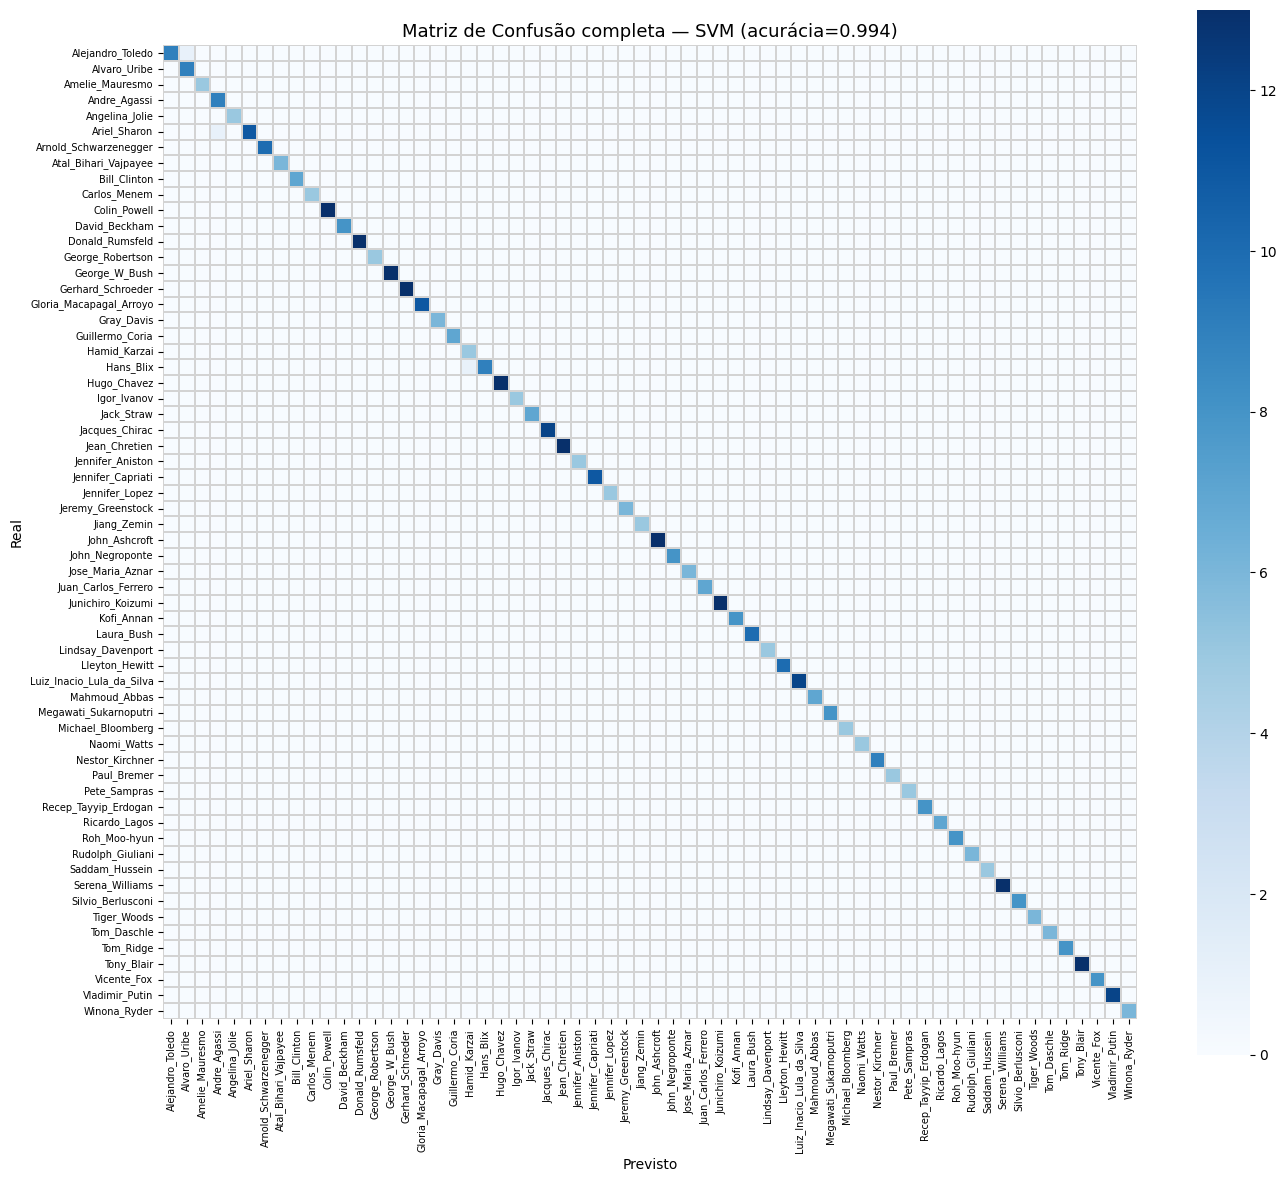


=== Erros do modelo SVM ===
3 erro(s) em 514 amostras de teste (0.6%):

  Real: Ariel_Sharon                 -> Previsto: Andre_Agassi
  Real: Alejandro_Toledo             -> Previsto: Alvaro_Uribe
  Real: Hans_Blix                    -> Previsto: Hamid_Karzai


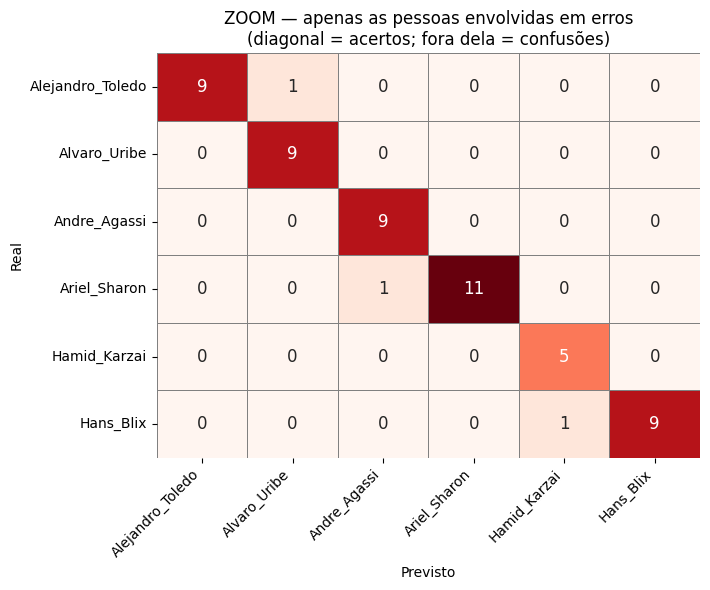

In [15]:
print('=== Comparação de acurácia ===')
print(f'  SVM: {acc_svm:.4f}')
print(f'  kNN: {acc_knn:.4f}')

# Modelo de melhor acurácia
melhor_nome, melhor_pred = ('SVM', y_pred_svm) if acc_svm >= acc_knn else ('kNN', y_pred_knn)

# --- Matriz de confusão completa (visão geral) ---
# Com 62 classes, escrever o número em cada célula deixa o gráfico ilegível.
# Aqui o que importa é ver a DIAGONAL forte (acertos). Os erros são células de
# valor 1, quase invisíveis nesta escala -> por isso fazemos o "zoom" abaixo.
cm = confusion_matrix(y_test, melhor_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm, annot=False, cmap='Blues', cbar=True, square=True,
            linewidths=0.3, linecolor='lightgray',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Matriz de Confusão completa — {melhor_nome} (acurácia={max(acc_svm, acc_knn):.3f})', fontsize=13)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.xticks(rotation=90, fontsize=7)
plt.yticks(rotation=0, fontsize=7)
plt.tight_layout()
plt.show()

# --- Lista dos erros ---
erros = np.where(y_test != melhor_pred)[0]
print(f'\n=== Erros do modelo {melhor_nome} ===')
if len(erros) == 0:
    print('Nenhum erro no conjunto de teste!')
else:
    print(f'{len(erros)} erro(s) em {len(y_test)} amostras de teste '
          f'({len(erros)/len(y_test)*100:.1f}%):\n')
    for i in erros:
        print(f'  Real: {le.classes_[y_test[i]]:<28} -> Previsto: {le.classes_[melhor_pred[i]]}')

# --- ZOOM: matriz só com as pessoas envolvidas em erros ---
# Recortamos da matriz completa apenas as linhas/colunas das pessoas que
# apareceram em algum erro. Vira uma matriz pequena e LEGÍVEL, onde:
#   - número na DIAGONAL  = fotos daquela pessoa que o modelo ACERTOU
#   - número FORA da diagonal = os ERROS (linha = quem era, coluna = chute do modelo)
if len(erros) > 0:
    classes_erro = sorted(set(y_test[erros]) | set(melhor_pred[erros]))
    sub_cm = cm[np.ix_(classes_erro, classes_erro)]
    nomes = le.classes_[classes_erro]

    plt.figure(figsize=(max(6, len(classes_erro) * 1.2), max(5, len(classes_erro) * 1.0)))
    sns.heatmap(sub_cm, annot=True, fmt='d', cmap='Reds', cbar=False,
                linewidths=0.5, linecolor='gray', annot_kws={'size': 12},
                xticklabels=nomes, yticklabels=nomes)
    plt.title('ZOOM — apenas as pessoas envolvidas em erros\n'
              '(diagonal = acertos; fora dela = confusões)', fontsize=12)
    plt.xlabel('Previsto')
    plt.ylabel('Real')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

## 9. Conclusões

**Objetivos atingidos.** Construímos um classificador de faces multiclasse a partir de um dataset que originalmente é só um conjunto de imagens. O algoritmo de Aprendizado de Máquina aplicado foi nosso (**SVM** e **kNN**); a `face_recognition` entrou apenas como **extrator de features**, transformando cada foto em um vetor de 128 dimensões.

**Resultados deste experimento** (62 pessoas, 2055 fotos, 75% treino / 25% teste):

| Modelo | Acurácia |
|--------|----------|
| SVM (RBF) | **0,9942** |
| kNN (k=5, distância) | 0,9922 |

Os dois modelos ficaram praticamente empatados e muito altos. Isso mostra que **o trabalho pesado está na representação dos dados**, não no classificador: como os embeddings de 128 dimensões já separam muito bem as identidades, qualquer classificador razoável acerta quase tudo. O SVM levou ligeira vantagem por achar fronteiras de decisão mais flexíveis; o kNN, mesmo sendo o algoritmo mais simples possível, chegou quase no mesmo lugar — confirmando que as faces de uma mesma pessoa caem **próximas** no espaço de 128 dimensões.

**Sobre os erros.** Com ~99% de acerto, sobram pouquíssimos casos (listados na seção anterior). Eles tendem a se concentrar em pessoas com **poucas fotos** ou com aparência parecida, exatamente onde há menos exemplos para o modelo aprender — reflexo direto do desbalanceamento do LFW.

**O papel da manipulação dos dados.** O resultado só foi possível por causa do tratamento feito antes do modelo: filtrar pessoas com fotos suficientes, equilibrar a quantidade por pessoa, descartar imagens sem rosto, dividir de forma estratificada e padronizar. Sem essas etapas, o problema seria intratável (milhares de classes com 1 foto) ou enviesado (poucas pessoas dominando o treino).

**Limitações e próximos passos:**
- A acurácia alta é em parte porque selecionamos só pessoas "fáceis" (com muitas fotos). Diminuir `MIN_FACES_PER_PERSON` aumenta o número de classes e torna o problema mais difícil — bom para estressar os modelos.
- Usar **validação cruzada** (em vez de um único split) daria uma estimativa mais confiável.
- Ajuste de hiperparâmetros com **`GridSearchCV`** (valores de `C`/`gamma` no SVM, `k` no kNN).
- Comparar com outros classificadores vistos na disciplina (ex.: Regressão Logística, Naive Bayes) sobre os mesmos embeddings.